# 05 – Training curves: baseline run (run1_256)

Plotting the training vs validation loss, validation mIoU and per-class IoU.

#### Goal
Turn history.json into 2–3 plots that show how training went.

In [1]:
import matplotlib.pyplot as plt 
import json 

In [2]:
# load the history 
with open('../results/run1_256/history.json', 'r') as f:
    history = json.load(f) # a list of dicts, one per epoch
    # pull out the lists, one value per epoch 
    epochs = [h["epoch"] for h in history]
    train_loss = [h["train_loss"] for h in history]
    val_loss = [h["val_loss"] for h in history]
    miou = [h["miou"] for h in history]

##### Plot 1, loss

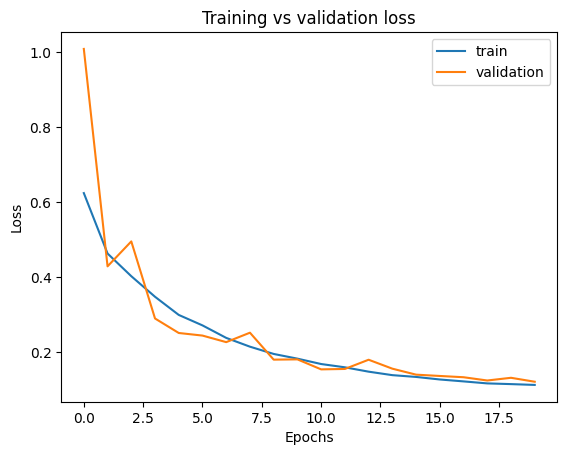

In [ ]:
# shows whether the model overfits (if the lines drift apart)

plt.plot(epochs, train_loss, label="train")
plt.plot(epochs, val_loss, label="validation")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs validation loss")
plt.legend()
plt.xticks(range(0, 20, 2))
# save the figures 
plt.savefig("../results/run1_256/loss.png", dpi=150, bbox_inches="tight")
plt.show()

##### Plot 2, mIoU per epoch

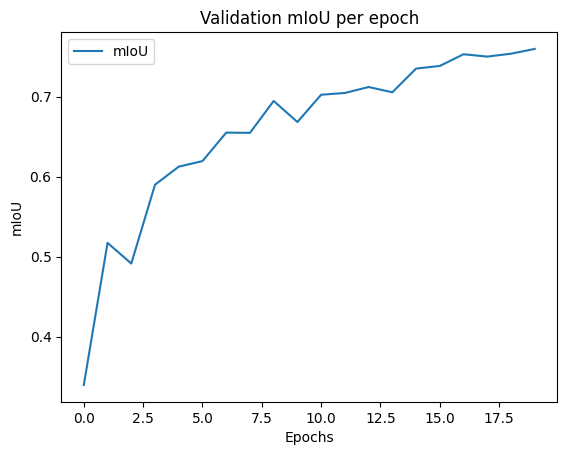

In [ ]:
# validation mIoU over the epochs

plt.plot(epochs, miou, label="mIoU")
plt.xlabel("Epochs")
plt.ylabel("mIoU")
plt.title("Validation mIoU per epoch")
plt.legend()
plt.xticks(range(0, 20, 2))
plt.savefig("../results/run1_256/miou.png", dpi=150, bbox_inches="tight")
plt.show()


#### Plot 3, per-class IoU

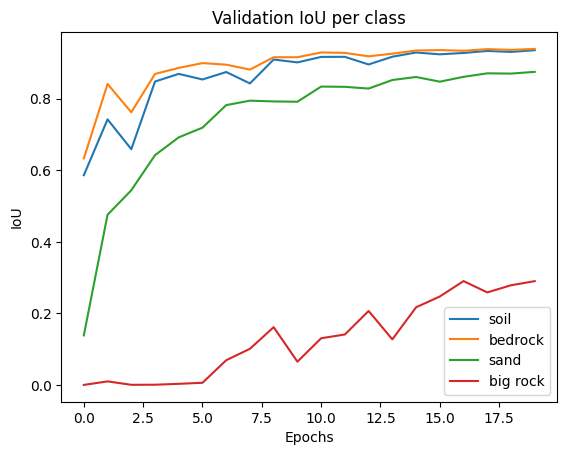

In [ ]:
# one line per class (soil, bedrock, sand, big rock)
# "iou" entry is a list of 4 values per epoch
# three classes climb quickly and level off, while big rock stays low and only starts rising late

classes = ["soil", "bedrock", "sand", "big rock"]
for c in range(4):
    iou = [h["iou"][c] for h in history]
    # plotting once per class
    plt.plot(epochs, iou, label=classes[c])
plt.xlabel("Epochs")
plt.ylabel("IoU")
plt.title("Validation IoU per class")
plt.legend()
plt.xticks(range(0, 20, 2))
plt.savefig("../results/run1_256/iou.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

**Loss (Training vs validation)**
- Both losses fall steadily and end close together (train 0.113, validation 0.121 at epoch 19).
- Validation loss never rises above training loss for long, so there is **no sign of overfitting**.
- Validation loss is noisy in the first epochs (e.g. epochs 2 and 7) and stabilises as the cosine schedule lowers the learning rate.

**Validation mIoU**
- Rises from 0.34 (epoch 0) to **0.760 (epoch 19)**, the best epoch.
- Still increasing at the end, so a longer run would likely improve the result.

**Per-class IoU**
- Soil, bedrock and sand learn quickly: all above 0.8 by about epoch 4–6, and 0.87–0.94 at the end.
- **Big rock** stays near 0 for the first 5 epochs, then rises slowly and unevenly to 0.29. It is the main weakness of the model, consistent with its rarity (0.75% of labelled pixels) and inconsistent labelling found in data exploration.
- → Next experiment: imbalance-aware loss (weighted cross-entropy or Dice) to improve big rock.

**Baseline settings:** U-Net from scratch, 256×256, batch size 8, Adam (lr 1e-3), cosine schedule, 20 epochs, mixed precision.